# Lösung L31 - Schaetzung des Leistungsdichtespektrums nach Bartlett und Welch

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l32.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lwelch.m `](./lwelch.m) 

```matlab
% ##################################################################################
% ##  Funktion: lwelch.m;   Welch- bzw. Bartlettverfahren                         ##
% ##################################################################################
%
% function Sxx = lwelch(x,K,windowtype[,NFFT[,overlap]])
%
% Schaetzung der spektralen Leistungsdichte nach dem Welch-Ansatz
%   x             Datenfolge (Zeilenvektor)
%   K             Anzahl der zu mittelnden Periodogramme = #Teilfolgen
%   windowtype    Fensterfunktion (z.B. 'hamming'=> Welch-Verfahren,
%                                       'boxcar' => Bartlett-Verfahren).
%  [NFFT]         FFT-Laenge (optional)
%  [overlap]      zusaetzliche Mittelung mit den Periodogrammen der 
%                 um fix(L/2) verschobenen Teilfolgen (falls das  
%                 optionale Argument vorhanden ist)
% Beispiel:  Sxx = lwelch(x,4,'boxcar',1024);

function Sxx = lwelch(x,K,windowtype,NFFT,~)

L = floor(length(x)/K);
if nargin<4
    NFFT=nextpow2(L); 
end

% Fensterfunktion der Laenge
eval(['fenster =',windowtype,'(L);']);  % L berechnen (Spaltenvektor)
AL  = fenster.'*fenster;                % Normierungskonstante
Sxx = zeros(1,NFFT);
kk  = (1:L);

for i = 0:K-1                           % Addition der Periodogramme
  yi = fenster.' .* x(kk+i*L);          % der nicht-ueberlappenden 
  Yi = fft(yi,NFFT);                    % Teilfolgen von x
  Sxx = Sxx + abs(Yi).^2;
end

if nargin > 4                           % zusaetzliche Addition der  
  kk  = (1:L) + fix(L/2);               % Periodogramme der ueber-
  for i = 0:K-2                         % lappenden Teilfolgen von x
    yi = fenster' .* x(kk+i*L);
    Yi = fft(yi,NFFT);
    Sxx = Sxx + abs(Yi).^2;
  end
  Sxx = Sxx/AL/(2*K-1);                 % Normierung auf AL und 
else                                    % Anzahl der Mittelungen (=2K-1)
  Sxx = Sxx/AL/K;                       % Normierung auf AL und
end                                     % Anzahl der Mittelungen (=K) 
% #####  EOF  #####
```

This exercise is part of the book [[KK22]](https://doi.org/10.1007/978-3-663-09805-8) for which the respective exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/books/dsv/).

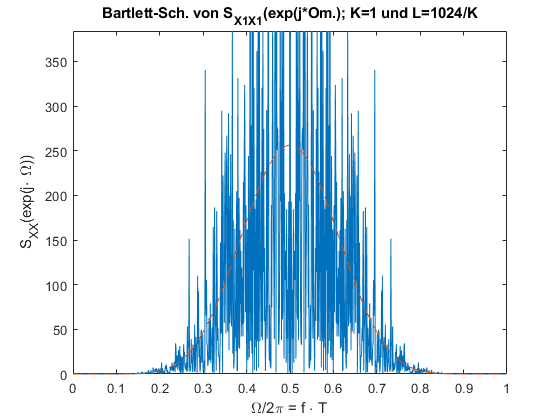

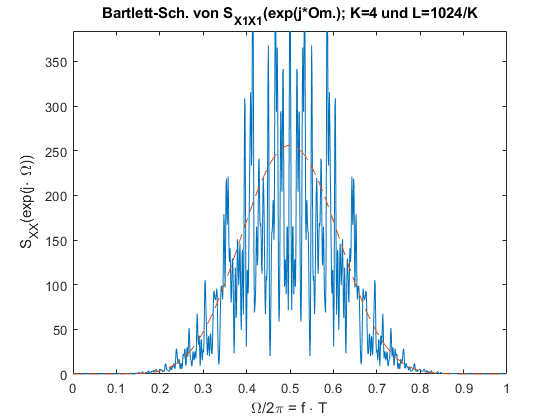

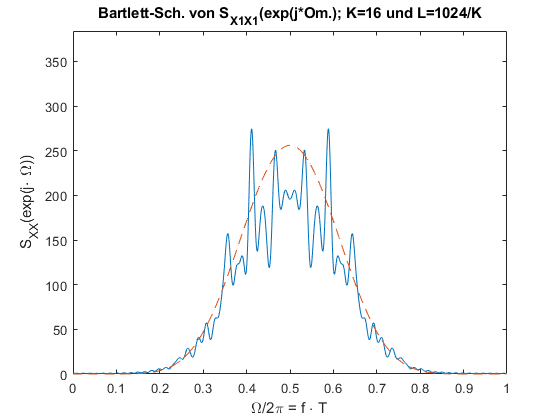

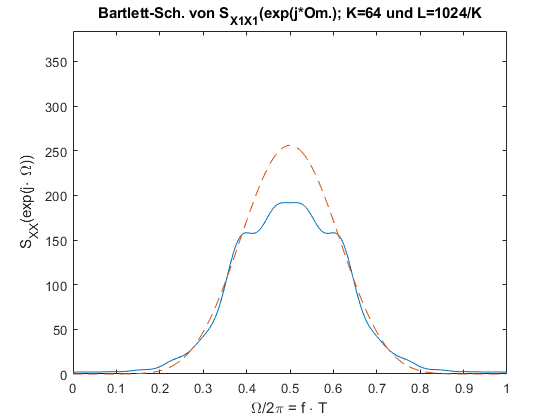

In [1]:
N     = 2^10; 
N_vor = 500; 

n  = randn(1,N+N_vor);             

h1 = [1 -4 6 -4 +1];  x1_all = filter(h1,1,n); x1=x1_all(N_vor+1:length(x1_all));
h2 = [1 0.8];         x2_all = filter(1,h2,n); x2=x2_all(N_vor+1:length(x2_all));

% "Wahres" Leistungsdichtespektrum zum Vergleich
NFFT = 2^10;                    
Sx1x1 = abs(fft(h1,NFFT)).^2;                axis_Sx1=[0 1 0  1.5*max(Sx1x1)];
Sx2x2 = ones(1,NFFT)./abs(fft(h2,NFFT)).^2;  axis_Sx2=[0 1 0  1.5*max(Sx2x2)];
fT = 0:1/NFFT:1-1/NFFT;
v_K = [1 4 16 64];

% BARTLETT fuer x1
win='boxcar';                                       
for k=v_K
    S_xx=lwelch(x1,k,win,NFFT);
    
    % # grafische Ausgabe # %
    figure; 
    plot(fT,S_xx); 
    hold on;
    plot(fT,Sx1x1,'--');
    axis(axis_Sx1);
    xlabel('\Omega/2\pi = f \cdot T');
    ylabel('S_{XX}(exp(j\cdot \Omega))');
    title(sprintf('Bartlett-Sch. von S_{X1X1}(exp(j*Om.); K=%d und L=%d/K',k, N));
    text(0.73,900,'== Periodogramm');
end

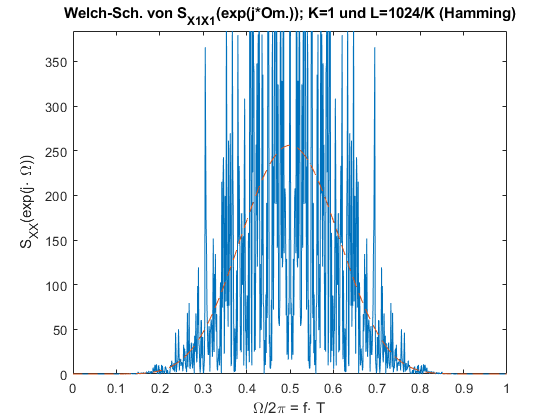

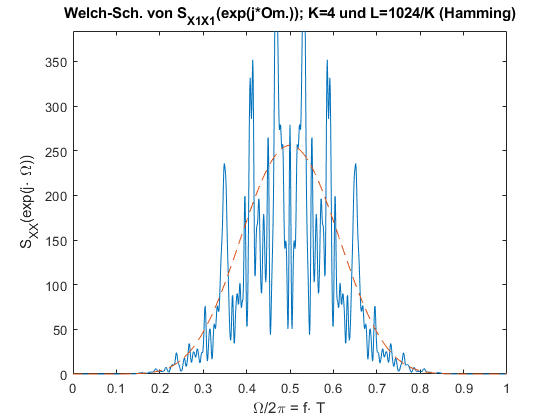

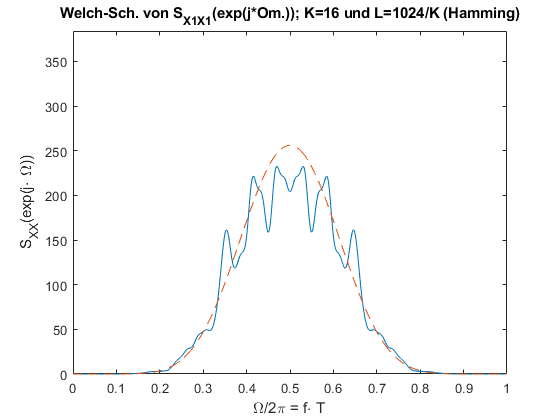

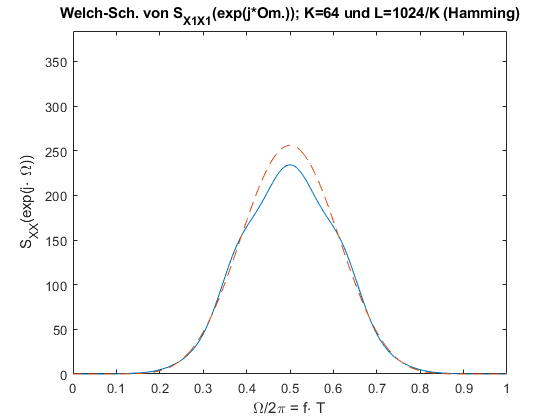

In [2]:
% WELCH-Verf. mit Hamming fuer x1
win='hamming';                       
for k=v_K
    S_xx=lwelch(x1,k,win,NFFT);

    % # grafische Ausgabe # %
    figure;  
    plot(fT,S_xx);  
    hold on; 
    plot(fT,Sx1x1,'--'); 
    axis(axis_Sx1);
    xlabel('\Omega/2\pi = f\cdot T');
    ylabel('S_{XX}(exp(j\cdot \Omega))');
    title(sprintf('Welch-Sch. von S_{X1X1}(exp(j*Om.)); K=%d und L=%d/K (Hamming)',k, N));
end

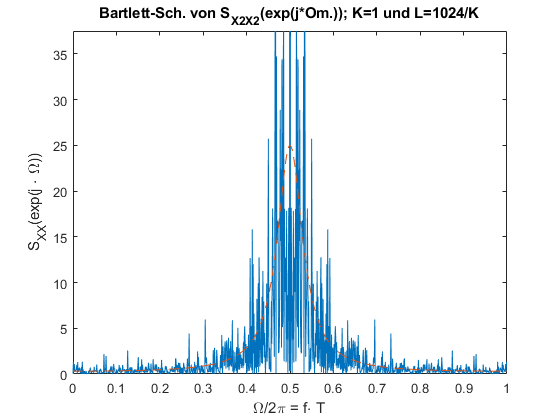

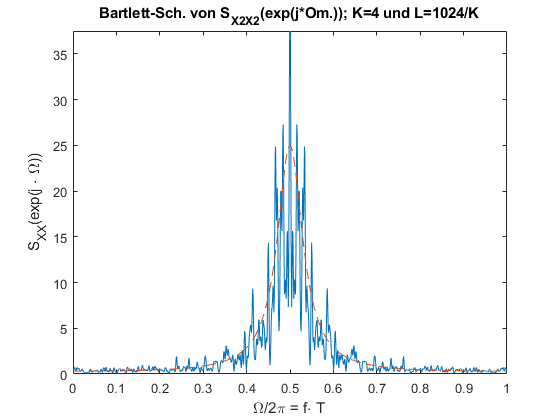

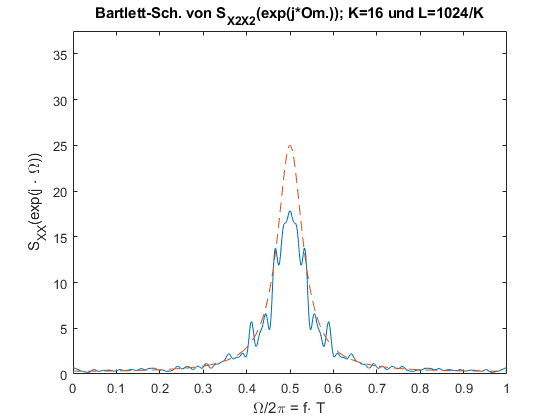

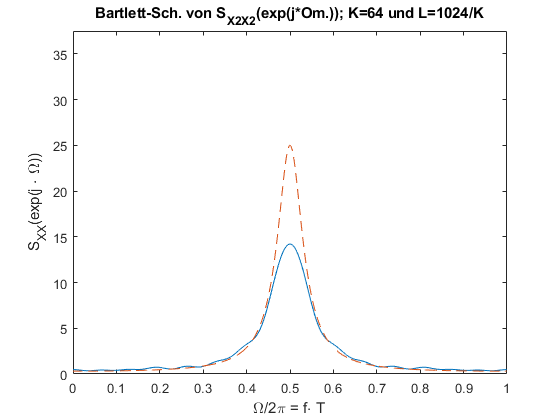

In [3]:
% BARTLETT fuer x2
win='boxcar';                                       
for k=v_K
    S_xx=lwelch(x2,k,win,NFFT);
    
    % # grafische Ausgabe # %
    figure; 
    plot(fT,S_xx);  
    hold on;
    plot(fT,Sx2x2,'--');
    axis(axis_Sx2); 
    xlabel('\Omega/2\pi = f\cdot T');
    ylabel('S_{XX}(exp(j \cdot \Omega))');
    title(sprintf('Bartlett-Sch. von S_{X2X2}(exp(j*Om.)); K=%d und L=%d/K',k, N));
    text(0.73,900,'== Periodogramm');
end

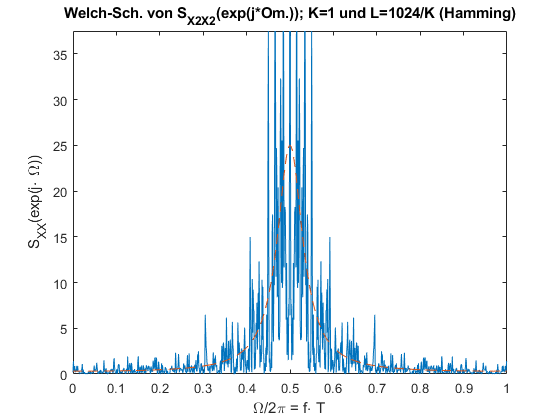

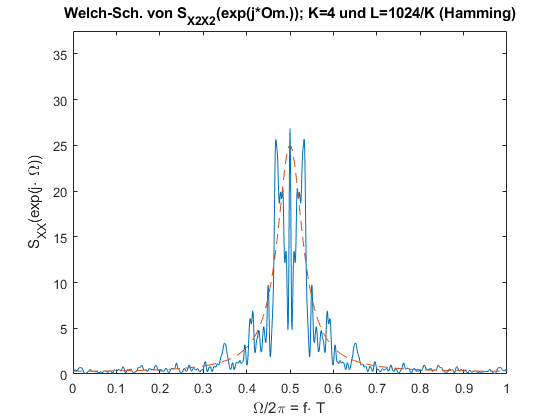

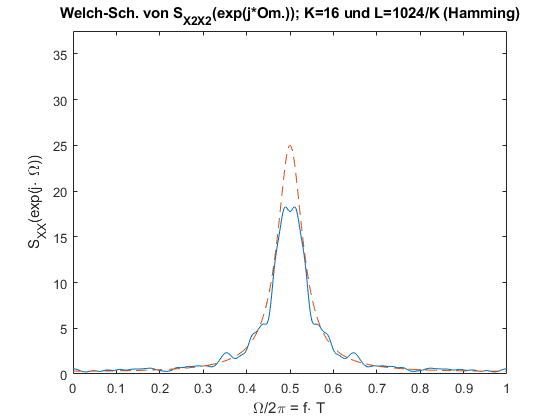

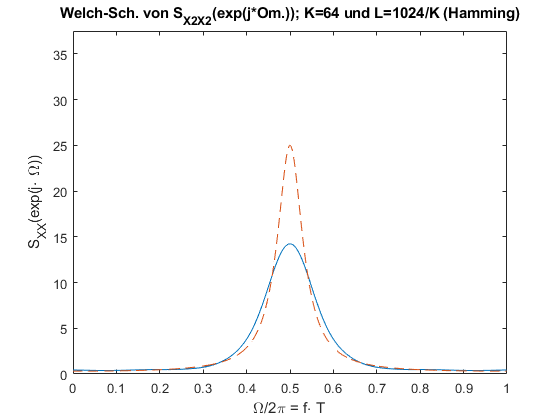

In [4]:
% WELCH-Verf. mit Hamming fuer x2
win='hamming';                       
for k=v_K
    S_xx=lwelch(x2,k,win,NFFT);
    
    % # grafische Ausgabe # %
    figure; 
    plot(fT,S_xx); 
    hold on;
    plot(fT,Sx2x2,'--');
    axis(axis_Sx2); 
    xlabel('\Omega/2\pi = f\cdot T');
    ylabel('S_{XX}(exp(j\cdot \Omega))');
    title(sprintf('Welch-Sch. von S_{X2X2}(exp(j*Om.)); K=%d und L=%d/K (Hamming)',k, N));
end

# Referenzen

[[KK22]](https://doi.org/10.1007/978-3-663-09805-8) K.-D. Kammeyer, K. Kroschel: "Digitale Signalverarbeitung - Filterung und Spektralanalyse", Springer Vieweg, 2022. Exercises can be downloaded [here](https://www.comm.uni-bremen.de/en/publications/dsv/).